# 01 · The review dataset

**What this does.** Builds the dataset every later model learns from. It holds reviews from three kinds of shop (restaurants, groceries and appliances), cleaned and labelled positive, neutral or negative, then split into training, validation and test sets.

**Why it matters.** A model is only as good as its data, and its scores are only honest if the test set is truly unseen. Two choices here guard that:
1. **Whole shops go to one split.** If a restaurant's reviews sat in both training and test, the model could learn that restaurant's quirks and look better than it really is.
2. **Duplicates are removed before splitting**, so a copy of a training review can't turn up in the test set.

The labels come from star ratings: 1–2★ is negative, 3★ neutral, 4–5★ positive. That is a shortcut, since stars don't always match the words. We check how often they disagree at the end.

**Settings.** `DEV = True` builds the quick development sample (about 7,000 reviews per domain). The full run sets it to `False` (50,000 per domain).

In [1]:
DEV = False

In [2]:
import time

import matplotlib.pyplot as plt
import pandas as pd

from review_intel import config
from review_intel.data.build import build_dataset

FIG = config.REPORTS_DIR / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"negative": "#d9381e", "neutral": "#b98900", "positive": "#00a862"}
suffix = "_dev" if DEV else ""

## 1. Where the reviews come from

| Domain | Source | Licence |
|---|---|---|
| Restaurant | Yelp Open Dataset (Kaggle mirror), businesses in the *Restaurants* category | Academic and non-commercial use; we never republish review text |
| Grocery | Amazon Reviews 2023, *Grocery and Gourmet Food* (McAuley Lab) | Research use; not redistributed |
| Appliances | Amazon Reviews 2023, *Appliances* | Research use; not redistributed |

Each file is read **line by line**: the Yelp file alone is 5 GB, more than the laptop has free. A *reservoir sample* keeps a fair random selection while reading, so every review in the file has the same chance of being picked, and only the sample is ever held in memory.

In [3]:
start = time.time()
df, report = build_dataset(dev=DEV)
print(f"Built {len(df):,} reviews in {time.time() - start:,.0f} s")
df.head(3)

Built 150,000 reviews in 167 s


[Output removed before publishing: it shows review text, which the Yelp and Amazon licences don't allow us to republish. Run the notebook locally to see it.]


## 2. What cleaning removed

For each domain, we sample about 30% more reviews than needed, then drop:
- **short** reviews (under 15 characters: too little to learn from);
- **non-English** reviews (the models are English-only);
- reviews with **no star rating**;
- **duplicates** (same text once case, punctuation and digits are ignored).

The table counts each reason. *kept* is what goes into the dataset.

In [4]:
counts = pd.DataFrame(report).fillna(0).astype(int).T
counts = counts[[c for c in ["sampled", "short", "non_english", "no_stars", "duplicate", "kept"] if c in counts]]
counts

,sampled,short,non_english,duplicate,kept
restaurant,65000,2,43,3,50000
grocery,65000,2448,326,628,50000
appliances,65000,2441,516,1329,50000


## 3. How positive is each domain?

This shows the share of reviews per label in each domain. Online reviews lean heavily positive, so **accuracy alone would flatter a model** that just says "positive" every time. That's why later notebooks report **macro F1**, which weighs the three labels equally.

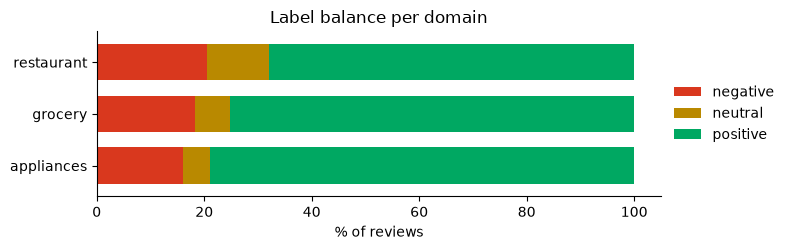

label,negative,neutral,positive
domain,,,
appliances,16.1,5.1,78.8
grocery,18.3,6.5,75.2
restaurant,20.5,11.5,68.0


In [5]:
balance = pd.crosstab(df["domain"], df["label"], normalize="index").reindex(columns=config.LABELS) * 100
ax = balance.plot.barh(stacked=True, color=[COLORS[l] for l in config.LABELS], figsize=(8, 2.6), width=0.7)
ax.set_xlabel("% of reviews"); ax.set_ylabel(""); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title("Label balance per domain")
plt.tight_layout(); plt.savefig(FIG / f"01_label_balance{suffix}.png"); plt.show()
balance.round(1)

## 4. How long are reviews?

Length matters for the transformer model: it reads at most 256 word-pieces (about 190 words), so this checks how many reviews get cut short.

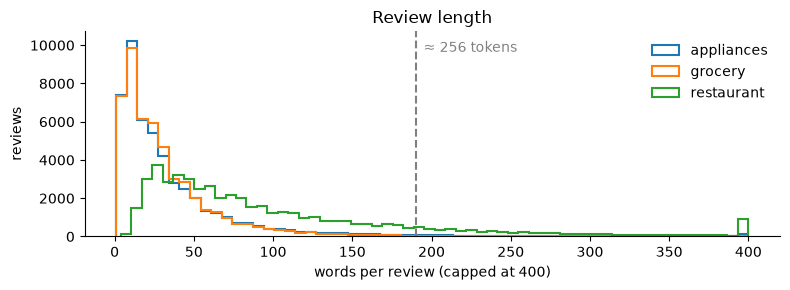

            median    75%     max
domain                           
appliances    22.0   44.0  1571.0
grocery       22.0   42.0  1077.0
restaurant    71.0  128.0   986.0
Reviews longer than ~190 words: 5.0%


In [6]:
words = df["text"].str.split().str.len()
fig, ax = plt.subplots(figsize=(8, 3))
for domain, part in df.assign(words=words).groupby("domain"):
    ax.hist(part["words"].clip(upper=400), bins=60, histtype="step", linewidth=1.5, label=domain)
ax.axvline(190, color="grey", linestyle="--"); ax.text(195, ax.get_ylim()[1] * 0.9, "≈ 256 tokens", color="grey")
ax.set_xlabel("words per review (capped at 400)"); ax.set_ylabel("reviews"); ax.legend(frameon=False)
ax.set_title("Review length")
plt.tight_layout(); plt.savefig(FIG / f"01_review_length{suffix}.png"); plt.show()
print(words.groupby(df["domain"]).describe()[["50%", "75%", "max"]].rename(columns={"50%": "median"}))
print(f"Reviews longer than ~190 words: {(words > 190).mean():.1%}")

## 5. When were the reviews written?

This checks the dates: the time range of each source, and whether any period dominates.

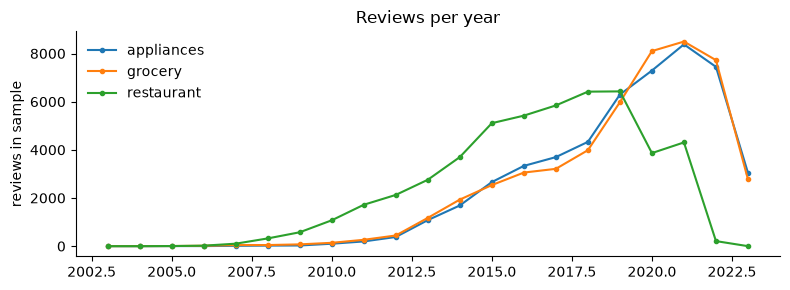

,min,max
domain,,
appliances,2003-03-04,2023-09-07
grocery,2004-09-09,2023-09-04
restaurant,2005-03-09,2022-01-19


In [7]:
per_year = df.assign(year=df["date"].str[:4].astype(int)).groupby(["year", "domain"]).size().unstack(fill_value=0)
ax = per_year.plot(figsize=(8, 3), marker=".")
ax.set_ylabel("reviews in sample"); ax.set_xlabel(""); ax.set_title("Reviews per year"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / f"01_reviews_per_year{suffix}.png"); plt.show()
df.groupby("domain")["date"].agg(["min", "max"])

## 6. What the reviews look like

One random review per domain and label, shortened to 200 characters.

In [8]:
examples = df.groupby(["domain", "label"]).sample(1, random_state=config.SEED)
examples.assign(text=examples["text"].str.slice(0, 200))[["domain", "label", "stars", "text"]]

[Output removed before publishing: it shows review text, which the Yelp and Amazon licences don't allow us to republish. Run the notebook locally to see it.]


## 7. When stars and words disagree

The labels come from stars, so some will be "wrong" by the words: a 5★ review that says *terrible*, or a 1★ review that says *love it*. A rough count tells us how noisy the labels are. These reviews are where any model will look wrong even when it reads the text correctly.

In [9]:
neg_words = r"\b(?:terrible|awful|horrible|worst|disgusting)\b"
pos_words = r"\b(?:love|excellent|amazing|perfect|best)\b"
happy_but_negative = df[(df["stars"] == 5) & df["text"].str.contains(neg_words, case=False)]
angry_but_positive = df[(df["stars"] == 1) & df["text"].str.contains(pos_words, case=False)]
print(f"5★ reviews using a strongly negative word: {len(happy_but_negative):,} ({len(happy_but_negative) / (df['stars'] == 5).sum():.1%} of 5★)")
print(f"1★ reviews using a strongly positive word: {len(angry_but_positive):,} ({len(angry_but_positive) / (df['stars'] == 1).sum():.1%} of 1★)")
pd.concat([happy_but_negative.head(2), angry_but_positive.head(2)])[["domain", "stars", "text"]].assign(text=lambda d: d["text"].str.slice(0, 200))

5★ reviews using a strongly negative word: 335 (0.4% of 5★)
1★ reviews using a strongly positive word: 1,404 (7.5% of 1★)


[Output removed before publishing: it shows review text, which the Yelp and Amazon licences don't allow us to republish. Run the notebook locally to see it.]


## 8. The split, and a leak check

Each shop's reviews must be in **exactly one** split. The check below must print **0**.

In [10]:
leaks = (df.groupby("group_id")["split"].nunique() > 1).sum()
print("Shops appearing in more than one split:", leaks)
assert leaks == 0
sizes = pd.crosstab(df["domain"], df["split"]).reindex(columns=["train", "val", "test"])
sizes.loc["total"] = sizes.sum()
print("Distinct shops per domain:", df.groupby("domain")["group_id"].nunique().to_dict())
sizes

Shops appearing in more than one split: 0
Distinct shops per domain: {'appliances': 16673, 'grocery': 31221, 'restaurant': 20740}


split,train,val,test
domain,,,
appliances,39976,5028,4996
grocery,40000,5000,5000
restaurant,40000,5000,5000
total,119976,15028,14996


## 9. Data card

Writes `pipeline/reports/data_card.md`, a one-page summary of the dataset (sources, licences, cleaning counts, balance, splits) that travels with the models.

In [11]:
card = f"""# Data card · review dataset{' (development sample)' if DEV else ''}

Built by `pipeline/notebooks/01_data.ipynb` with seed {config.SEED}.

## Sources and licences
- **Restaurant:** Yelp Open Dataset via Kaggle (`{config.YELP_KAGGLE}`), businesses in the *Restaurants* category. Academic/non-commercial use only; review text is never republished.
- **Grocery / Appliances:** Amazon Reviews 2023 (`{config.AMAZON_DATASET}`), categories {', '.join(config.AMAZON_CATEGORIES.values())}. Research use; not redistributed.

## Labels
Stars → label: 1–2 negative, 3 neutral, 4–5 positive. Stars and text sometimes disagree (§7 of the notebook).

## Cleaning (per domain)
{counts.to_markdown()}

## Label balance (% of reviews)
{balance.round(1).to_markdown()}

## Splits (reviews; whole shops per split, grouped by product or business)
{sizes.to_markdown()}

Date range: {df['date'].min()} to {df['date'].max()}. Rows: {len(df):,}.
"""
(config.REPORTS_DIR / "data_card.md").write_text(card, encoding="utf-8")
print(card[:600], "…")

# Data card · review dataset

Built by `pipeline/notebooks/01_data.ipynb` with seed 42.

## Sources and licences
- **Restaurant:** Yelp Open Dataset via Kaggle (`yelp-dataset/yelp-dataset`), businesses in the *Restaurants* category. Academic/non-commercial use only; review text is never republished.
- **Grocery / Appliances:** Amazon Reviews 2023 (`McAuley-Lab/Amazon-Reviews-2023`), categories Grocery_and_Gourmet_Food, Appliances. Research use; not redistributed.

## Labels
Stars → label: 1–2 negative, 3 neutral, 4–5 positive. Stars and text sometimes disagree (§7 of the notebook).

## Cleanin …


## Key findings

*Full dataset: 150,000 reviews, 50,000 per domain. The 20k development run gave the same picture within about 1 point.*

1. **The data is clean, and the splits are honest.** No shop appears in more than one split. Each domain splits about 80/10/10 by review count (119,976 / 15,028 / 14,996 overall; whole shops can't be cut in half), across 68,634 distinct shops.

2. **Reviews lean heavily positive, especially on Amazon.** Positive reviews make up 68.0% of restaurant reviews, 75.2% of grocery and 78.8% of appliances. **Neutral is rare (5–12%).** So a lazy model could reach ~75% accuracy by always saying "positive". That's why later notebooks use **macro F1** and class-weighted training, and why the neutral class will be the hardest.

3. **Restaurant reviews are three times longer** (median 71 words, against 22 on Amazon). Only about 5% of reviews exceed the transformer's ~256-token limit, so truncation loses little.

4. **Stars and words sometimes disagree.**
   - About **7.5% of 1★ reviews** contain a strongly positive word. Often it's "I'll start with the positives…" before a complaint, or praise for staff alongside a bad experience.
   - Only 0.4% of 5★ reviews contain a strongly negative word.

   This label noise caps how well any model can score against star-based labels. It's also exactly the kind of mixed review that **aspect-level** sentiment (notebook 04) handles better than one label.

5. **A cleaning bug was caught here.** The first language filter dropped about 3% of Amazon reviews as non-English, but most of them were short or ALL-CAPS English ("Yum. Delicious!"). That would have quietly removed many of the strongest reviews. After the fix, about 0.7% of grocery and 0.8% of appliance reviews are dropped, and almost all of those are Spanish (see ERROR_LOG, 2026-11-01).

6. **A label leak was caught and removed (after notebook 02's first run).** Amazon gives untitled reviews an automatic title like "Five Stars", which matched the rating 99.8% of the time, on about 8–9% of Amazon reviews. Those titles are now dropped. That is also why many more Amazon reviews fall under *short*: "Five Stars. Yum!" became just "Yum!", too short to keep (see ERROR_LOG, 2026-11-01).

7. **The time spans are similar:** 2003–2023 (restaurants 2005 to January 2022). 87% of sampled reviews are from 2015 onwards. Monthly trends in the shop report will rest on recent years.

**Next:** the baseline model (notebook 02).